In [1]:
#import necesary libaries 
import pandas as pd
import numpy as np

In [2]:
#import data
df = pd.read_csv("kickstarter_clean (1).csv")

In [3]:
df.head()

,main_category,deadline,goal,launched,pledged,state,backers,country,usd_pledged_real,usd_goal_real,campaign_length,success,percent_funded
0,Publishing,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,1533.95,58,0,0.000000
1,Film & Video,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,2421.0,30000.00,59,0,8.070000
2,Film & Video,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,45000.00,44,0,0.488889
3,Music,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,5000.00,29,0,0.020000
4,Food,2016-04-01,50000.0,2016-02-26 13:38:27,52375.0,successful,224,US,52375.0,50000.00,34,1,104.750000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 331675 entries, 0 to 331674
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   main_category     331675 non-null  object 
 1   deadline          331675 non-null  object 
 2   goal              331675 non-null  float64
 3   launched          331675 non-null  object 
 4   pledged           331675 non-null  float64
 5   state             331675 non-null  object 
 6   backers           331675 non-null  int64  
 7   country           331675 non-null  object 
 8   usd_pledged_real  331675 non-null  float64
 9   usd_goal_real     331675 non-null  float64
 10  campaign_length   331675 non-null  int64  
 11  success           331675 non-null  int64  
 12  percent_funded    331675 non-null  float64
dtypes: float64(5), int64(3), object(5)
memory usage: 32.9+ MB


In [5]:
#clean data further
df = df[df['state'].isin(['successful', 'failed', 'canceled'])]
df = df.drop(columns=[
    'pledged',
    'usd_pledged_real',
    'backers',
    'percent_funded',
    'success',        # if present
    'ID',
    'goal'
], errors='ignore')

In [6]:
#datetime
df['launched'] = pd.to_datetime(df['launched'])
df['deadline'] = pd.to_datetime(df['deadline'])

df['campaign_length'] = (df['deadline'] - df['launched']).dt.days
df['launch_month'] = df['launched'].dt.month

In [7]:
df = df.drop(columns=['deadline', 'launched'])

In [8]:
df.head()

,main_category,state,country,usd_goal_real,campaign_length,launch_month
0,Publishing,failed,GB,1533.95,58,8
1,Film & Video,failed,US,30000.00,59,9
2,Film & Video,failed,US,45000.00,44,1
3,Music,failed,US,5000.00,29,3
4,Food,successful,US,50000.00,34,2


In [9]:
df = df.dropna()


In [10]:
#split states 
X = df.drop('state', axis=1)
y = df['state']

In [11]:
X = pd.get_dummies(X, drop_first=True)

In [12]:
df.columns

Index(['main_category', 'state', 'country', 'usd_goal_real', 'campaign_length',
       'launch_month'],
      dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 331675 entries, 0 to 331674
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   main_category    331675 non-null  object 
 1   state            331675 non-null  object 
 2   country          331675 non-null  object 
 3   usd_goal_real    331675 non-null  float64
 4   campaign_length  331675 non-null  int64  
 5   launch_month     331675 non-null  int32  
dtypes: float64(1), int32(1), int64(1), object(3)
memory usage: 13.9+ MB


In [14]:
# test train split 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [15]:
#train random forest model
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [16]:
#predict
y_pred = model.predict(X_test)

In [17]:
#clasify 
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      failed       0.67      0.74      0.70     39551
  successful       0.54      0.46      0.50     26784

    accuracy                           0.63     66335
   macro avg       0.61      0.60      0.60     66335
weighted avg       0.62      0.63      0.62     66335



In [18]:
#confussion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[29116 10435]
 [14381 12403]]


In [19]:
import pandas as pd

feature_importance = pd.Series(model.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False)

print(feature_importance.head(10))

usd_goal_real               0.500033
campaign_length             0.229354
launch_month                0.153839
main_category_Music         0.011168
main_category_Technology    0.008882
main_category_Theater       0.008753
main_category_Fashion       0.006878
main_category_Comics        0.006102
main_category_Food          0.005836
country_US                  0.005786
dtype: float64


In [20]:
#accuracy score
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.6258988467626442


In [21]:
print(y.unique())

['failed' 'successful']


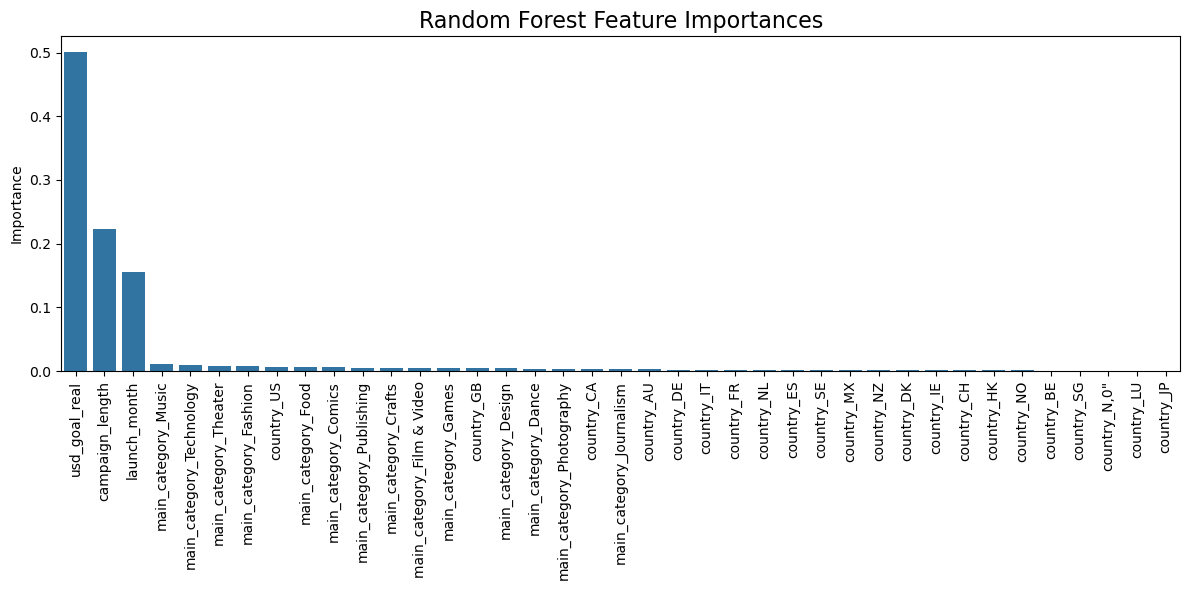

In [27]:
##graphs
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Fit the Random Forest if not already done
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

# Feature importance
importances = rf.feature_importances_
features = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12,6))
plt.title("Random Forest Feature Importances", fontsize=16)
sns.barplot(x=[features[i] for i in indices], y=importances[indices])
plt.xticks(rotation=90)
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [31]:
#logistic regression model

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


              precision    recall  f1-score   support

      failed       0.66      0.81      0.73     39551
  successful       0.59      0.39      0.47     26784

    accuracy                           0.64     66335
   macro avg       0.63      0.60      0.60     66335
weighted avg       0.63      0.64      0.62     66335

[[32198  7353]
 [16345 10439]]


In [28]:
#feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)